# EDA CULTIVA: rotina de estudos e hábitos de saúde

Este notebook investiga dois conjuntos de dados para apoiar ideias de produto para Larissa (estudante) e Rafael (hábitos e mudança de peso). As explicações usam palavras simples, mas as conclusões continuam cuidadosas: um gráfico mostra pistas, não prova que uma coisa causou outra.

**Aviso importante sobre os dados:** a descrição do Kaggle para o conjunto de estudantes fala de questionários de gestão do tempo, notas e frequência. Ela não confirma medidas de horas de sono, lazer, estudo ou estresse. O código vai procurar essas colunas; se não existirem, vai explicar o limite e analisar apenas o que os arquivos realmente contêm. O conjunto de peso tem cerca de 100 participantes, então seus resultados são pistas iniciais, não regras médicas.

In [19]:
# Estas ferramentas ajudam o notebook a encontrar e arrumar os dados.
from pathlib import Path
import re
import unicodedata

import kagglehub
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

# Usamos cores e tamanhos consistentes para os gráficos ficarem fáceis de ler.
sns.set_theme(style="whitegrid", palette="deep", context="notebook")
plt.rcParams["figure.figsize"] = (10, 5)


def normalizar_texto(texto):
    """Deixa nomes de arquivos e colunas mais fáceis de comparar."""
    texto = unicodedata.normalize("NFKD", str(texto)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", "", texto.lower())


def escolher_csv(arquivos, palavras_chave, evitar=()):
    """Escolhe o arquivo principal usando pistas do nome, sem depender de um caminho fixo."""
    candidatos = [
        arquivo for arquivo in arquivos
        if not any(normalizar_texto(palavra) in normalizar_texto(arquivo.stem) for palavra in evitar)
    ]
    if not candidatos:
        candidatos = arquivos
    return max(
        candidatos,
        key=lambda arquivo: sum(
            normalizar_texto(palavra) in normalizar_texto(arquivo.stem)
            for palavra in palavras_chave
        ),
    )


def baixar_e_carregar(dataset_id, palavras_chave, evitar=()):
    # O KaggleHub baixa o conjunto e informa em qual pasta ele foi guardado.
    pasta = Path(kagglehub.dataset_download(dataset_id))
    arquivos_csv = sorted(pasta.rglob("*.csv"))
    if not arquivos_csv:
        raise FileNotFoundError(f"Nenhum CSV foi encontrado em {pasta}")

    print(f"Arquivos CSV encontrados para {dataset_id}:")
    for arquivo in arquivos_csv:
        print(f" - {arquivo.name}")

    arquivo_principal = escolher_csv(arquivos_csv, palavras_chave, evitar)
    # utf-8-sig também entende arquivos que começam com uma marca de texto comum em planilhas.
    dados = pd.read_csv(arquivo_principal, encoding="utf-8-sig")
    print(f"\nArquivo escolhido: {arquivo_principal.name}")
    print(f"Tamanho: {dados.shape[0]} linhas e {dados.shape[1]} colunas")
    return dados, arquivos_csv


def colunas_por_pistas(dataframe, pistas):
    """Procura colunas por nomes parecidos e devolve apenas as que existem."""
    encontradas = []
    for coluna in dataframe.columns:
        nome = normalizar_texto(coluna)
        if any(normalizar_texto(pista) in nome for pista in pistas):
            encontradas.append(coluna)
    return list(dict.fromkeys(encontradas))


def insight_correlacao(matriz, alvo):
    """Conta em palavras simples quais relações numéricas são mais fortes."""
    if alvo not in matriz.columns or len(matriz.columns) < 2:
        print("Não há colunas numéricas suficientes para comparar com o resultado.")
        return
    relacoes = matriz[alvo].drop(labels=[alvo], errors="ignore").dropna()
    if relacoes.empty:
        print("Não apareceu uma correlação calculável com o resultado escolhido.")
        return
    relacoes = relacoes.reindex(relacoes.abs().sort_values(ascending=False).index)
    coluna = relacoes.index[0]
    valor = relacoes.iloc[0]
    direcao = "sobem juntas" if valor > 0 else "uma tende a subir quando a outra desce"
    print(
        f"Pista descritiva: '{coluna}' e '{alvo}' {direcao} "
        f"nesta amostra (correlação {valor:.2f}). Isso não prova causa e efeito."
    )

## 1. Importação dos dados com KaggleHub

O KaggleHub é como um entregador: ele busca os arquivos públicos do Kaggle informa onde os deixou. Como cada conjunto pode ter mais de um CSV, vamos listar os arquivos e escolher aquele cujo nome parece ser o principal. Assim evitamos abrir por engano uma planilha auxiliar.

In [20]:
# Estes identificadores dizem exatamente quais conjuntos públicos queremos baixar.
dataset_larissa = "xiaowenlimarketing/international-student-time-management"
dataset_rafael = "abdullah0a/comprehensive-weight-change-prediction"

# Cada chamada baixa o conjunto e abre o CSV principal em uma tabela do pandas.
df_larissa, arquivos_larissa = baixar_e_carregar(
    dataset_larissa,
    palavras_chave=("international students time management", "time management data"),
    evitar=("sheet2",),
)
df_rafael, arquivos_rafael = baixar_e_carregar(
    dataset_rafael,
    palavras_chave=("weight change dataset", "weight change"),
)

# Sheet2 é a chave que explica as perguntas e quantos pontos vale cada resposta.
arquivo_sheet2 = next(
    (arquivo for arquivo in arquivos_larissa if normalizar_texto(arquivo.stem) == "sheet2"),
    None,
)
if arquivo_sheet2 is None:
    raise FileNotFoundError("O arquivo auxiliar Sheet2.csv não foi encontrado no conjunto de Larissa.")

# A planilha usa duas linhas de cabeçalho; separamos as perguntas dos nomes das opções.
sheet2_bruto = pd.read_csv(arquivo_sheet2, header=None, encoding="utf-8-sig")
opcoes_sheet2 = sheet2_bruto.iloc[1, 2:7].tolist()
df_perguntas = sheet2_bruto.iloc[2:, :7].copy()
df_perguntas.columns = ["Order", "Questions", *opcoes_sheet2]
df_perguntas = df_perguntas.dropna(subset=["Order", "Questions"])
df_perguntas["Order"] = pd.to_numeric(df_perguntas["Order"], errors="coerce")
df_perguntas = df_perguntas.dropna(subset=["Order"])
df_perguntas["Order"] = df_perguntas["Order"].astype(int)
for opcao in opcoes_sheet2:
    df_perguntas[opcao] = pd.to_numeric(df_perguntas[opcao], errors="coerce")

print(f"Sheet2 carregada: {len(df_perguntas)} perguntas e suas regras de pontuação.")

Arquivos CSV encontrados para xiaowenlimarketing/international-student-time-management:
 - International students Time management data.csv
 - Sheet2.csv

Arquivo escolhido: International students Time management data.csv
Tamanho: 125 linhas e 21 colunas
Arquivos CSV encontrados para abdullah0a/comprehensive-weight-change-prediction:
 - weight_change_dataset.csv

Arquivo escolhido: weight_change_dataset.csv
Tamanho: 100 linhas e 13 colunas
Sheet2 carregada: 12 perguntas e suas regras de pontuação.


## 2. Limpeza e visão geral dos dados

Antes de desenhar, olhamos a tabela como quem confere os ingredientes antes de cozinhar. As primeiras linhas mostram exemplos; os tipos dizem se a coluna parece número ou palavra; os nulos mostram espaços sem resposta; e duplicatas ajudam a encontrar registros repetidos. Primeiro vamos inspecionar, sem apagar nada escondido.

In [21]:
def mostrar_visao_geral(nome, dataframe):
    print(f"\n{'=' * 78}\n{nome}: primeiras linhas")
    display(dataframe.head())  # Um pequeno pedaço ajuda a reconhecer o que cada linha representa.

    print("\nTipos de dados")
    display(dataframe.dtypes.rename("tipo").to_frame())  # Número e texto não devem ser tratados do mesmo jeito.

    print("\nRespostas ausentes por coluna")
    faltantes = dataframe.isna().sum().rename("quantidade").to_frame()
    faltantes["percentual"] = (faltantes["quantidade"] / max(len(dataframe), 1) * 100).round(1)
    display(faltantes.sort_values("quantidade", ascending=False))

    print(f"Linhas repetidas por inteiro: {dataframe.duplicated().sum()}")
    print("\nResumo estatístico: números e categorias")
    display(dataframe.describe(include="all").T)  # Mediana, média e contagens resumem a tabela.

    numericas = dataframe.select_dtypes(include="number")
    if not numericas.empty:
        print("\nResumo apenas das colunas numéricas")
        display(numericas.describe().T)
    else:
        print("Não há colunas numéricas reconhecidas automaticamente nesta tabela.")

    print("\nExemplos de valores das colunas de texto")
    categoricas = dataframe.select_dtypes(exclude="number")
    if categoricas.empty:
        print("Não há colunas de texto/categoria.")
    else:
        for coluna in categoricas.columns[:12]:
            exemplos = dataframe[coluna].dropna().astype(str).str.strip().unique()[:8]
            print(f"{coluna}: {list(exemplos)}")


mostrar_visao_geral("Larissa: gestão do tempo e estudos", df_larissa)
mostrar_visao_geral("Rafael: hábitos e mudança de peso", df_rafael)


Larissa: gestão do tempo e estudos: primeiras linhas


,Number,Age,Gender,Nationality,Program,Course,English,Academic,Attendance,6,...,8,9,10,11,12,13,14,15,16,17
0,1,31-35,M,Korea,PM,Social Sciences and Humanities,60%~70%,NaN,S0,Disagree,...,Strong Agree,Neither,Agree,Neither,Disagree,Strong Disagree,Strong Agree,Neither,Disagree,Agree
1,2,26-30,M,China,PM,Science and engineering,60%~70%,50%~59%,S3,Strong Agree,...,Neither,Disagree,Agree,Neither,Disagree,Strong Disagree,Neither,Agree,Neither,Disagree
2,3,26-30,M,Kenya,PM,Business,60%~70%,NaN,S0,Disagree,...,Agree,Disagree,Agree,Agree,Disagree,Strong Disagree,Disagree,Strong Agree,Strong Agree,Disagree
3,4,21-25,M,Vietnam,PM,Law/Legal studies,60%~70%,60%~70%,S0,Disagree,...,Agree,Agree,Disagree,Agree,Neither,Neither,Neither,Neither,Disagree,Agree
4,5,21-25,M,China,PM,Business,60%~70%,50%~59%,S1,Neither,...,Neither,Neither,Disagree,Neither,Neither,Neither,Neither,Disagree,Neither,Agree



Tipos de dados


,tipo
Number,int64
Age,str
Gender,str
Nationality,str
Program,str
Course,str
English,str
Academic,str
Attendance,str
6,str



Respostas ausentes por coluna


,quantidade,percentual
Academic,22,17.6
9,7,5.6
English,6,4.8
Attendance,6,4.8
8,4,3.2
12,3,2.4
11,2,1.6
16,2,1.6
6,2,1.6
17,1,0.8


... (11 outputs left out)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Participant ID,100.0,NaN,NaN,NaN,50.5,29.011492,1.0,25.75,50.5,75.25,100.0
Age,100.0,NaN,NaN,NaN,37.91,12.219454,18.0,26.75,38.0,46.25,59.0
Gender,100,2,M,57,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Current Weight (lbs),100.0,NaN,NaN,NaN,171.533,30.333856,100.0,153.65,172.15,192.475,238.2
BMR (Calories),100.0,NaN,NaN,NaN,2518.206,364.431221,1566.5,2255.05,2519.5,2805.975,3390.8
Daily Calories Consumed,100.0,NaN,NaN,NaN,3518.292,513.313097,2030.9,3233.3,3636.05,4000.0,4000.0
Daily Caloric Surplus/Deficit,100.0,NaN,NaN,NaN,1000.091,371.560827,82.5,766.95,1013.1,1253.325,1922.5
Weight Change (lbs),100.0,NaN,NaN,NaN,-2.779817,7.443719,-35.678115,-5.012312,0.1,1.85,5.0
Duration (weeks),100.0,NaN,NaN,NaN,6.92,3.515277,1.0,4.0,7.0,10.0,12.0
Physical Activity Level,100,4,Lightly Active,31,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Resumo apenas das colunas numéricas


,count,mean,std,min,25%,50%,75%,max
Participant ID,100.0,50.500000,29.011492,1.000000,25.750000,50.50,75.250,100.0
Age,100.0,37.910000,12.219454,18.000000,26.750000,38.00,46.250,59.0
Current Weight (lbs),100.0,171.533000,30.333856,100.000000,153.650000,172.15,192.475,238.2
BMR (Calories),100.0,2518.206000,364.431221,1566.500000,2255.050000,2519.50,2805.975,3390.8
Daily Calories Consumed,100.0,3518.292000,513.313097,2030.900000,3233.300000,3636.05,4000.000,4000.0
Daily Caloric Surplus/Deficit,100.0,1000.091000,371.560827,82.500000,766.950000,1013.10,1253.325,1922.5
Weight Change (lbs),100.0,-2.779817,7.443719,-35.678115,-5.012312,0.10,1.850,5.0
Duration (weeks),100.0,6.920000,3.515277,1.000000,4.000000,7.00,10.000,12.0
Stress Level,100.0,4.810000,2.576879,1.000000,2.750000,5.00,7.000,9.0
Final Weight (lbs),100.0,168.750000,30.588004,98.200000,149.550000,169.80,188.300,232.5



Exemplos de valores das colunas de texto
Gender: ['M', 'F']
Physical Activity Level: ['Sedentary', 'Very Active', 'Lightly Active', 'Moderately Active']
Sleep Quality: ['Excellent', 'Good', 'Fair', 'Poor']


### O que significa cada pergunta? Sheet2.csv

A segunda planilha é o guia do questionário. Ela traz as afirmações e a pontuação de cada resposta. Isso importa porque algumas perguntas apontam para dificuldades: nelas, “concordo” recebe menos pontos. Outras descrevem bons hábitos e recebem mais pontos quando a pessoa concorda. Vamos respeitar essa regra pergunta por pergunta, em vez de usar uma escala única para tudo.

In [22]:
# Estas traduções ajudam a entender os itens sem mudar o texto original da fonte.
traducao_perguntas = {
    6: "Sente que sua vida não tem rumo ou propósito definido?",
    7: "Você nunca tem dificuldade para organizar as coisas que precisa fazer?",
    8: "Persiste em uma atividade até terminá-la?",
    9: "Sente que as tarefas do dia não parecem importantes?",
    10: "Planeja suas atividades de um dia para o outro?",
    11: "Costuma deixar as coisas para a última hora?",
    12: "Muda sem rumo de uma atividade para outra durante o dia?",
    13: "Desiste do que planejou só porque seus amigos não querem?",
    14: "Acha que usa seu tempo de forma suficiente?",
    15: "Fica entediado facilmente com as atividades do dia a dia?",
    16: "Seus interesses ou atividades importantes mudam com frequência?",
    17: "Sabe quanto tempo gasta em cada dever de casa?",
}
df_perguntas["Pergunta em português"] = df_perguntas["Order"].map(traducao_perguntas)
colunas_exibicao = ["Order", "Questions", "Pergunta em português", *opcoes_sheet2]
display(df_perguntas[colunas_exibicao])

# Cada pergunta tem a própria chave. A planilha de respostas usa “Neither”,
# enquanto Sheet2 escreve a opção completa “Neither Agree or Disagree”.
alias_neutro = normalizar_texto("Neither Agree or Disagree")
pontuacoes_por_pergunta = {}
for _, pergunta in df_perguntas.iterrows():
    numero_pergunta = int(pergunta["Order"])
    coluna_resposta = str(numero_pergunta)
    if coluna_resposta not in df_larissa.columns:
        print(f"A resposta da pergunta {numero_pergunta} não existe no arquivo principal; será ignorada.")
        continue

    mapa_resposta = {
        normalizar_texto(opcao): int(pergunta[opcao])
        for opcao in opcoes_sheet2
        if pd.notna(pergunta[opcao])
    }
    if alias_neutro in mapa_resposta:
        mapa_resposta["neither"] = mapa_resposta[alias_neutro]

    respostas_normalizadas = df_larissa[coluna_resposta].astype("string").map(normalizar_texto)
    pontuacoes_por_pergunta[f"Q{numero_pergunta}"] = respostas_normalizadas.map(mapa_resposta)

df_pontuacoes = pd.DataFrame(pontuacoes_por_pergunta, index=df_larissa.index)
colunas_itens = list(df_pontuacoes.columns)
df_pontuacoes["respostas_validas"] = df_pontuacoes[colunas_itens].notna().sum(axis=1)
# Exigimos ao menos 9 de 12 respostas (75%) para não calcular a média com muitas lacunas.
minimo_respostas = int(np.ceil(len(colunas_itens) * 0.75))
df_pontuacoes["score_medio_gestao_tempo"] = df_pontuacoes[colunas_itens].mean(axis=1).where(
    df_pontuacoes["respostas_validas"] >= minimo_respostas
)

print("Pontuação calculada com a chave específica de cada pergunta.")
print("Em todos os itens, a pontuação maior indica a direção considerada mais favorável pela própria chave da Sheet2.")
print(f"Índice médio calculado apenas para estudantes com pelo menos {minimo_respostas} respostas válidas.")
print("Enunciados e tradução:")
display(df_perguntas[["Order", "Pergunta em português", "Questions"]])

,Order,Questions,Pergunta em português,Strong agree,Agree,Neither Agree or Disagree,Disagree,Strong disagree
2,6,"You often feel that your life is aimless, with...",Sente que sua vida não tem rumo ou propósito d...,1,2,3,4,5
3,7,You never have trouble organizing the things y...,Você nunca tem dificuldade para organizar as c...,5,4,3,2,1
4,8,"Once you've started an activity, you persist a...",Persiste em uma atividade até terminá-la?,5,4,3,2,1
5,9,Sometimes you feel that the things you have to...,Sente que as tarefas do dia não parecem import...,1,2,3,4,5
6,10,You will plan your activities from day to day.,Planeja suas atividades de um dia para o outro?,5,4,3,2,1
7,11,You tend to leave things to the last minute?,Costuma deixar as coisas para a última hora?,1,2,3,4,5
8,12,You tend to change rather aimlessly from one a...,Muda sem rumo de uma atividade para outra dura...,1,2,3,4,5
9,13,You give up the things that you planning to do...,Desiste do que planejou só porque seus amigos ...,1,2,3,4,5
10,14,You think you do enough with your time.,Acha que usa seu tempo de forma suficiente?,5,4,3,2,1
11,15,You are easy to get bored with your day-today ...,Fica entediado facilmente com as atividades do...,1,2,3,4,5


Pontuação calculada com a chave específica de cada pergunta.
Em todos os itens, a pontuação maior indica a direção considerada mais favorável pela própria chave da Sheet2.
Índice médio calculado apenas para estudantes com pelo menos 9 respostas válidas.
Enunciados e tradução:


,Order,Pergunta em português,Questions
2,6,Sente que sua vida não tem rumo ou propósito d...,"You often feel that your life is aimless, with..."
3,7,Você nunca tem dificuldade para organizar as c...,You never have trouble organizing the things y...
4,8,Persiste em uma atividade até terminá-la?,"Once you've started an activity, you persist a..."
5,9,Sente que as tarefas do dia não parecem import...,Sometimes you feel that the things you have to...
6,10,Planeja suas atividades de um dia para o outro?,You will plan your activities from day to day.
7,11,Costuma deixar as coisas para a última hora?,You tend to leave things to the last minute?
8,12,Muda sem rumo de uma atividade para outra dura...,You tend to change rather aimlessly from one a...
9,13,Desiste do que planejou só porque seus amigos ...,You give up the things that you planning to do...
10,14,Acha que usa seu tempo de forma suficiente?,You think you do enough with your time.
11,15,Fica entediado facilmente com as atividades do...,You are easy to get bored with your day-today ...


## 3. Distribuição de rotina: estudo, sono e lazer (Larissa)

## 4. Matriz de correlação: estudo, sono, estresse e desempenho

## 5. Análise de sobrecarga: padrões de estresse

Uma correlação é uma pista sobre duas coisas que mudam juntas; ela não prova que uma causou a outra. Também não vamos chamar uma nota de questionário de “horas de sono”. O código abaixo procura nomes claros de horas, sono, estresse e desempenho. Se não encontrar as medidas, ele explica o que falta e mostra apenas os dados numéricos realmente disponíveis.

Não encontrei medidas de horas de estudo, sono ou lazer; por isso não vou inventar uma rotina diária.


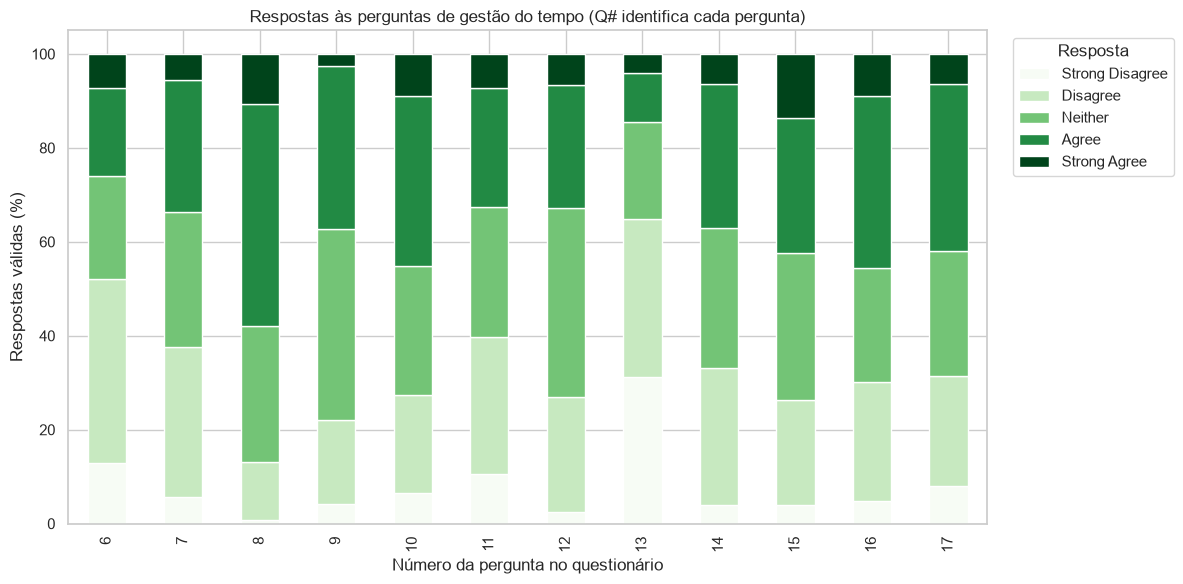

No gráfico, os números Q6 a Q17 substituem os enunciados longos para caberem no eixo.
Use esta legenda para ler cada número; ela vem das perguntas traduzidas da Sheet2.csv:


,Número no gráfico,Pergunta em português
2,6,Sente que sua vida não tem rumo ou propósito d...
3,7,Você nunca tem dificuldade para organizar as c...
4,8,Persiste em uma atividade até terminá-la?
5,9,Sente que as tarefas do dia não parecem import...
6,10,Planeja suas atividades de um dia para o outro?
7,11,Costuma deixar as coisas para a última hora?
8,12,Muda sem rumo de uma atividade para outra dura...
9,13,Desiste do que planejou só porque seus amigos ...
10,14,Acha que usa seu tempo de forma suficiente?
11,15,Fica entediado facilmente com as atividades do...


A altura de cada cor é uma porcentagem das respostas válidas daquela pergunta, não horas do dia.


In [23]:
# Só aceitamos nomes que indiquem horas. Uma resposta sobre organização não é a mesma coisa que duração.
pistas_rotina = {
    "Estudo (horas)": ("studyhours", "hoursofstudy", "studytimehours", "dailyhoursstudying"),
    "Sono (horas)": ("sleephours", "hoursofsleep", "sleepdurationhours", "dailysleephours"),
    "Lazer (horas)": ("leisurehours", "hoursofleisure", "freetimehours", "hoursleisure"),
}
colunas_rotina = {
    rotulo: colunas_por_pistas(df_larissa, pistas)
    for rotulo, pistas in pistas_rotina.items()
}
colunas_rotina = {rotulo: colunas[0] for rotulo, colunas in colunas_rotina.items() if colunas}

if colunas_rotina:
    rotina = pd.DataFrame({
        rotulo: pd.to_numeric(df_larissa[coluna], errors="coerce")
        for rotulo, coluna in colunas_rotina.items()
    }).dropna(how="all")
    if not rotina.empty:
        # O boxplot mostra o meio da turma e a variação, sem esconder valores distantes.
        sns.boxplot(data=rotina, orient="h", color="#4C9F70")
        plt.title("Distribuição das horas de rotina registradas")
        plt.xlabel("Horas por dia")
        plt.ylabel("")
        plt.tight_layout()
        plt.show()
        display(rotina.describe().T)
        for coluna in rotina.columns:
            print(f"Mediana de {coluna}: {rotina[coluna].median():.2f} horas.")
else:
    print("Não encontrei medidas de horas de estudo, sono ou lazer; por isso não vou inventar uma rotina diária.")
    # Sem horas, usamos as respostas do questionário. Q6 significa a pergunta 6, não uma quantidade de horas.
    itens_questionario = [
        coluna for coluna in df_larissa.columns
        if str(coluna).strip().isdigit()
    ]
    categorias_resposta = ["Strong Disagree", "Disagree", "Neither", "Agree", "Strong Agree"]
    if itens_questionario:
        respostas = df_larissa[itens_questionario].apply(
            lambda coluna: coluna.astype("string").str.strip().value_counts()
        ).reindex(categorias_resposta).fillna(0).T
        # Percentuais permitem comparar perguntas mesmo quando algumas pessoas não responderam.
        respostas_percentual = respostas.div(respostas.sum(axis=1).replace(0, np.nan), axis=0) * 100
        respostas_percentual.plot(kind="bar", stacked=True, figsize=(12, 6), colormap="Greens")
        plt.title("Respostas às perguntas de gestão do tempo (Q# identifica cada pergunta)")
        plt.xlabel("Número da pergunta no questionário")
        plt.ylabel("Respostas válidas (%)")
        plt.legend(title="Resposta", bbox_to_anchor=(1.02, 1), loc="upper left")
        plt.tight_layout()
        plt.show()

        print("No gráfico, os números Q6 a Q17 substituem os enunciados longos para caberem no eixo.")
        print("Use esta legenda para ler cada número; ela vem das perguntas traduzidas da Sheet2.csv:")
        display(
            df_perguntas[["Order", "Pergunta em português"]]
            .rename(columns={"Order": "Número no gráfico"})
            .sort_values("Número no gráfico")
        )
        print("A altura de cada cor é uma porcentagem das respostas válidas daquela pergunta, não horas do dia.")
    else:
        print("Não há medidas de horas nem perguntas numeradas para desenhar esta distribuição.")

Medidas que o arquivo principal realmente oferece:
 - horas de estudo: não encontrado
 - sono/qualidade do sono: não encontrado
 - estresse: não encontrado
 - desempenho/frequência: ['Attendance']
Resultados incluídos na comparação: ['English (ponto médio aproximado da faixa)', 'Academic (ponto médio aproximado da faixa)', 'Attendance (ordem descrita no Kaggle)']


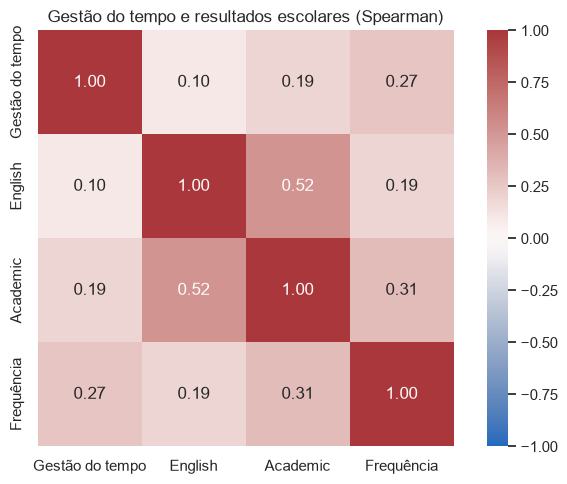

No heatmap, positivo significa que duas posições tendem a subir juntas; negativo, que tendem a ir em direções opostas.


,Order,Pergunta em português,Questions,media_pontuacao_favoravel,respostas_validas
11,15,Fica entediado facilmente com as atividades do...,You are easy to get bored with your day-today ...,2.744000,125
12,16,Seus interesses ou atividades importantes muda...,The important interests/activities in your lif...,2.804878,123
5,9,Sente que as tarefas do dia não parecem import...,Sometimes you feel that the things you have to...,2.864407,118
8,12,Muda sem rumo de uma atividade para outra dura...,You tend to change rather aimlessly from one a...,2.901639,122
3,7,Você nunca tem dificuldade para organizar as c...,You never have trouble organizing the things y...,2.960000,125
10,14,Acha que usa seu tempo de forma suficiente?,You think you do enough with your time.,3.064516,124
13,17,Sabe quanto tempo gasta em cada dever de casa?,You know how much time you spend on each of th...,3.088710,124
7,11,Costuma deixar as coisas para a última hora?,You tend to leave things to the last minute?,3.105691,123
6,10,Planeja suas atividades de um dia para o outro?,You will plan your activities from day to day.,3.201613,124
2,6,Sente que sua vida não tem rumo ou propósito d...,"You often feel that your life is aimless, with...",3.317073,123


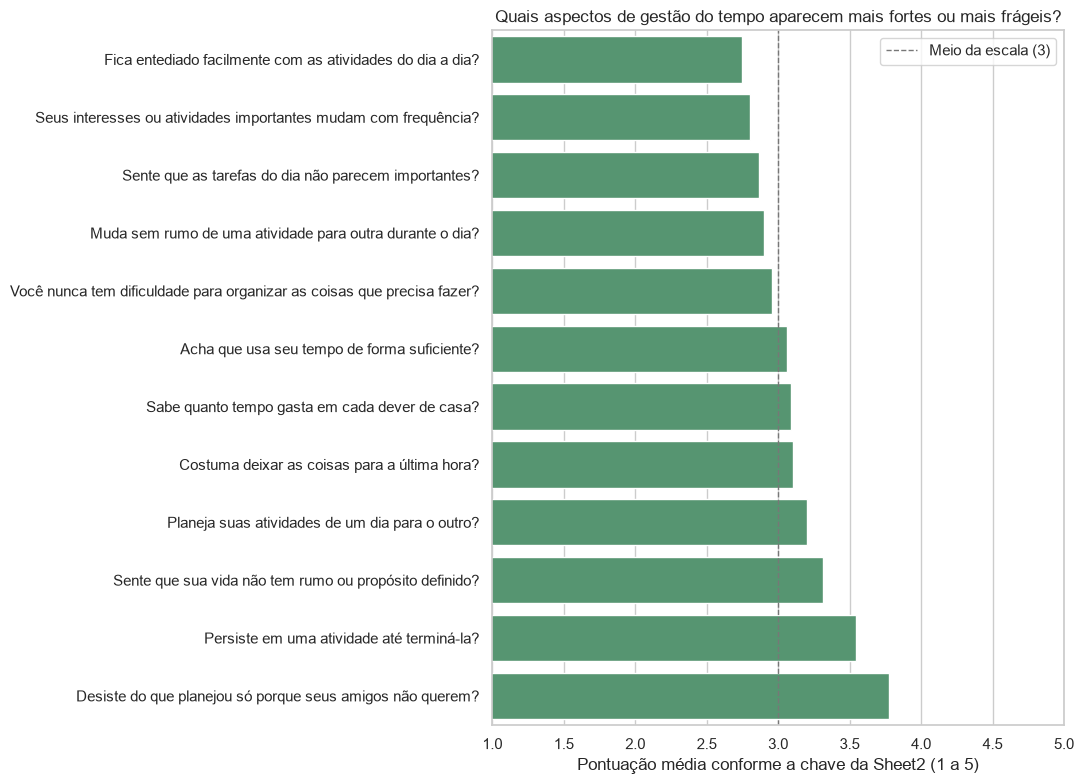

Pista nesta turma: menor média favorável no item 15 (Fica entediado facilmente com as atividades do dia a dia?): 2.74/5, com 125 respostas.
Maior média favorável no item 13 (Desiste do que planejou só porque seus amigos não querem?): 3.78/5, com 125 respostas.
A média mostra a resposta da turma a uma afirmação, não uma nota individual nem um diagnóstico.

Associação exploratória entre gestão do tempo e resultados escolares:
 - English (ponto médio aproximado da faixa): rho = 0.10; sobem juntas; 118 estudantes.
 - Academic (ponto médio aproximado da faixa): rho = 0.19; sobem juntas; 102 estudantes.
 - Attendance (ordem descrita no Kaggle): rho = 0.27; sobem juntas; 118 estudantes.

Limites: as perguntas medem percepções de organização e uso do tempo, não horas de sono, estresse ou tempo estudado.
As associações são exploratórias e não mostram que uma habilidade causou notas melhores ou presença maior.


In [24]:
# Estas colunas não existem no questionário, mas procuramos para manter o notebook útil se houver uma nova versão.
pistas_estudo = ("studyhours", "hoursofstudy", "studytimehours")
pistas_sono = ("sleephours", "hoursofsleep", "sleepduration", "sleepquality")
pistas_estresse = ("stresslevel", "stressscore", "perceivedstress", "stress")
pistas_desempenho = ("academicmark", "academicperformance", "grade", "attendance", "examresult")
print("Medidas que o arquivo principal realmente oferece:")
for nome, pistas in {
    "horas de estudo": pistas_estudo,
    "sono/qualidade do sono": pistas_sono,
    "estresse": pistas_estresse,
    "desempenho/frequência": pistas_desempenho,
}.items():
    achadas = colunas_por_pistas(df_larissa, pistas)
    print(f" - {nome}: {achadas if achadas else 'não encontrado'}")

# A nota acadêmica vem em faixas. O ponto médio é uma aproximação, não uma nota exata.
# O Kaggle descreve S0 como melhor frequência e S4 como menor frequência.
mapa_faixas = {"<40%": 35, "40%~49%": 44.5, "50%~59%": 54.5, "60%~70%": 65, ">70%": 75}
medidas_larissa = df_pontuacoes[colunas_itens + ["score_medio_gestao_tempo"]].copy()
for coluna in colunas_por_pistas(df_larissa, ("academic", "english")):
    medidas_larissa[f"{coluna} (ponto médio aproximado da faixa)"] = (
        df_larissa[coluna].astype("string").str.strip().map(mapa_faixas)
    )
for coluna in colunas_por_pistas(df_larissa, ("attendance",)):
    medidas_larissa[f"{coluna} (ordem descrita no Kaggle)"] = (
        df_larissa[coluna].astype("string").str.strip().str.upper().map({"S0": 5, "S1": 4, "S2": 3, "S3": 2, "S4": 1})
    )
medidas_larissa = medidas_larissa.apply(pd.to_numeric, errors="coerce").dropna(axis=1, how="all")

# Spearman é a correlação de Pearson depois de trocar valores por suas posições ordenadas.
# Fazemos esse passo explicitamente para não depender do pacote opcional SciPy.
postos_larissa = medidas_larissa.rank(method="average")
correlacao_larissa = postos_larissa.corr(method="pearson", min_periods=5)
coluna_indice = "score_medio_gestao_tempo"
# As colunas que não são perguntas Q6-Q17 nem o índice são os resultados escolares disponíveis.
colunas_resultado = [
    coluna for coluna in medidas_larissa.columns
    if coluna != coluna_indice and not str(coluna).startswith("Q")
]
print("Resultados incluídos na comparação:", colunas_resultado or "nenhum encontrado")

# O heatmap mostra só o resumo e os resultados escolares; os itens individuais aparecem no gráfico abaixo.
colunas_heatmap_larissa = [
    coluna for coluna in [coluna_indice, *colunas_resultado]
    if coluna in correlacao_larissa.columns
]
if len(colunas_heatmap_larissa) >= 2:
    correlacao_resumo = correlacao_larissa.loc[colunas_heatmap_larissa, colunas_heatmap_larissa]
    nomes_curto = {
        coluna_indice: "Gestão do tempo",
        **{
            coluna: ("Frequência" if "ordemdescrita" in normalizar_texto(coluna) else coluna.split(" (")[0])
            for coluna in colunas_resultado
        },
    }
    correlacao_resumo = correlacao_resumo.rename(index=nomes_curto, columns=nomes_curto)
    plt.figure(figsize=(7, 5))
    sns.heatmap(correlacao_resumo, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True)
    plt.title("Gestão do tempo e resultados escolares (Spearman)")
    plt.tight_layout()
    plt.show()
    print("No heatmap, positivo significa que duas posições tendem a subir juntas; negativo, que tendem a ir em direções opostas.")
else:
    print("Sem resultados escolares suficientes para montar um heatmap resumido.")

# O resumo mostra quais afirmações tiveram maior e menor pontuação favorável em média.
resumo_perguntas = df_perguntas[["Order", "Pergunta em português", "Questions"]].copy()
resumo_perguntas["media_pontuacao_favoravel"] = resumo_perguntas["Order"].map(
    lambda numero: df_pontuacoes.get(f"Q{int(numero)}", pd.Series(dtype=float)).mean()
)
resumo_perguntas["respostas_validas"] = resumo_perguntas["Order"].map(
    lambda numero: df_pontuacoes.get(f"Q{int(numero)}", pd.Series(dtype=float)).count()
)
display(resumo_perguntas.sort_values("media_pontuacao_favoravel"))

ordem_grafico = resumo_perguntas.sort_values("media_pontuacao_favoravel")
plt.figure(figsize=(11, 8))
sns.barplot(data=ordem_grafico, x="media_pontuacao_favoravel", y="Pergunta em português", color="#4C9F70")
plt.axvline(3, color="#777777", linestyle="--", linewidth=1, label="Meio da escala (3)")
plt.xlim(1, 5)
plt.xlabel("Pontuação média conforme a chave da Sheet2 (1 a 5)")
plt.ylabel("")
plt.title("Quais aspectos de gestão do tempo aparecem mais fortes ou mais frágeis?")
plt.legend()
plt.tight_layout()
plt.show()

pergunta_menor = resumo_perguntas.loc[resumo_perguntas["media_pontuacao_favoravel"].idxmin()]
pergunta_maior = resumo_perguntas.loc[resumo_perguntas["media_pontuacao_favoravel"].idxmax()]
print(
    f"Pista nesta turma: menor média favorável no item {int(pergunta_menor['Order'])} "
    f"({pergunta_menor['Pergunta em português']}): {pergunta_menor['media_pontuacao_favoravel']:.2f}/5, "
    f"com {int(pergunta_menor['respostas_validas'])} respostas."
)
print(
    f"Maior média favorável no item {int(pergunta_maior['Order'])} "
    f"({pergunta_maior['Pergunta em português']}): {pergunta_maior['media_pontuacao_favoravel']:.2f}/5, "
    f"com {int(pergunta_maior['respostas_validas'])} respostas."
)
print("A média mostra a resposta da turma a uma afirmação, não uma nota individual nem um diagnóstico.")

# Mostramos as relações do índice médio com cada resultado, junto do número de estudantes comparados.
if coluna_indice in medidas_larissa.columns and colunas_resultado:
    print("\nAssociação exploratória entre gestão do tempo e resultados escolares:")
    for resultado in colunas_resultado:
        pares = medidas_larissa[[coluna_indice, resultado]].dropna()
        if len(pares) >= 5 and pares.nunique().min() > 1:
            postos = pares.rank(method="average")
            valor = postos.iloc[:, 0].corr(postos.iloc[:, 1], method="pearson")
            direcao = "sobem juntas" if valor > 0 else "uma tende a subir quando a outra desce"
            print(f" - {resultado}: rho = {valor:.2f}; {direcao}; {len(pares)} estudantes.")
        else:
            print(f" - {resultado}: poucos pares válidos ou sem variação para calcular uma relação.")
else:
    print("Não há índice de questionário ou resultado escolar suficiente para comparar.")

print("\nLimites: as perguntas medem percepções de organização e uso do tempo, não horas de sono, estresse ou tempo estudado.")
print("As associações são exploratórias e não mostram que uma habilidade causou notas melhores ou presença maior.")

#### Como ler as perguntas e as correlações

A escala da `Sheet2.csv` dá pontos diferentes para cada resposta conforme a pergunta. Em perguntas sobre dificuldade, discordar pode ser mais favorável; em perguntas sobre bons hábitos, concordar pode ser mais favorável. Por isso, a pontuação maior quer dizer apenas “mais perto da direção favorável definida pela chave”, e não uma nota escolar ou um diagnóstico. O número Q6, Q7 etc. é o número da pergunta; a tabela acima mostra a tradução completa.

A linha tracejada em 3 marca o meio da escala de 1 a 5. Pontos acima ou abaixo ajudam a comparar as respostas da turma, mas não dizem o que uma pessoa específica deveria fazer. Para as faixas de notas e frequência, usamos Spearman: ele compara a ordem (mais baixo/mais alto), em vez de fingir que cada faixa representa uma medida exata. Correlação é como duas pistas que aparecem juntas; não prova que uma causou a outra.

## 6. Fatores de impacto: hábitos e mudança de peso (Rafael)

## 7. Análise de comportamento: atividade física e faixas de mudança

## 8. Padrões de consistência: hábitos pequenos e sustentáveis

O conjunto de Rafael tem aproximadamente 100 participantes, então cada pessoa representa uma parte importante do resultado. O Kaggle descreve a mudança de peso como uma estimativa relacionada ao balanço de calorias; por isso, uma correlação forte pode refletir a própria fórmula usada para criar o resultado. Vamos observar associações, não declarar causas.

In [25]:
# Antes de procurar atividade e sono, combinamos palavras que podem aparecer nos nomes das colunas.
# É como procurar uma pessoa pelo apelido: isso funciona como pista, mas vamos conferir o nome encontrado.
pistas_atividade = ("physicalactivity", "activityminutes", "exercise", "exercise minutes", "active minutes")
pistas_sono_rafael = ("sleephours", "sleepduration", "sleepquality")

In [26]:
# Fazemos uma cópia para conservar a tabela original exatamente como veio do Kaggle.
df_rafael_analise = df_rafael.copy()

# Um número pode chegar como texto. Só convertemos quando quase todos os valores parecem números.
for coluna in df_rafael_analise.select_dtypes(exclude="number").columns:
    texto = df_rafael_analise[coluna].astype("string").str.replace(",", "", regex=False)
    numero = pd.to_numeric(texto.str.replace(r"[^0-9.\\-]", "", regex=True), errors="coerce")
    quantidade_preenchida = df_rafael_analise[coluna].notna().sum()
    proporcao_numerica = numero.notna().sum() / max(quantidade_preenchida, 1)
    if proporcao_numerica >= 0.8 and numero.nunique(dropna=True) > 1:
        df_rafael_analise[coluna] = numero
        print(f"Converti '{coluna}' para número: os valores pareciam quantidades.")

# Conferimos as categorias antes de criar qualquer ordem para elas.
print("Colunas categóricas e exemplos de respostas:")
for coluna in df_rafael_analise.select_dtypes(exclude="number").columns:
    print(f" - {coluna}: {df_rafael_analise[coluna].dropna().astype(str).unique()[:8].tolist()}")

# A ordem só ajuda nos gráficos; os rótulos originais continuam guardados.
mapa_atividade = {
    "sedentary": 1,
    "lightly active": 2,
    "moderately active": 3,
    "very active": 4,
}
mapa_sono = {"poor": 1, "fair": 2, "good": 3, "excellent": 4}
for coluna in colunas_por_pistas(df_rafael_analise, pistas_atividade):
    df_rafael_analise[f"{coluna} (ordem aproximada)"] = (
        df_rafael_analise[coluna].astype("string").str.strip().str.lower().map(mapa_atividade)
    )
for coluna in colunas_por_pistas(df_rafael_analise, pistas_sono_rafael):
    df_rafael_analise[f"{coluna} (ordem aproximada)"] = (
        df_rafael_analise[coluna].astype("string").str.strip().str.lower().map(mapa_sono)
    )

# A regra IQR encontra pontos distantes do meio; isso é um aviso para olhar, não uma prova de erro.
resumo_extremos = []
for coluna in df_rafael_analise.select_dtypes(include="number").columns:
    nome_limpo = normalizar_texto(coluna)
    if "id" in nome_limpo or "participant" in nome_limpo or "ordemaproximada" in nome_limpo:
        continue
    valores = df_rafael_analise[coluna].dropna()
    if len(valores) < 4:
        continue
    q1, q3 = valores.quantile([0.25, 0.75])
    intervalo = q3 - q1
    limite_baixo = q1 - 1.5 * intervalo
    limite_alto = q3 + 1.5 * intervalo
    quantidade_extrema = int(((valores < limite_baixo) | (valores > limite_alto)).sum())
    resumo_extremos.append({
        "coluna": coluna,
        "valores_extremos_pela_regra_IQR": quantidade_extrema,
        "limite_inferior": limite_baixo,
        "limite_superior": limite_alto,
    })

print("\nChecagem de valores extremos pela regra IQR (nenhuma linha foi apagada):")
if resumo_extremos:
    display(pd.DataFrame(resumo_extremos).sort_values("valores_extremos_pela_regra_IQR", ascending=False))
else:
    print("Não há colunas numéricas com observações suficientes para essa checagem.")

# Definimos também as pistas para localizar o resultado e as medidas de alimentação.
pistas_peso = ("weightchange", "changeinweight", "weightchangeibs")
pistas_calorias = ("caloriesconsumed", "caloricintake", "calories", "caloricsurplus", "caloricdeficit", "surplusdeficit")
colunas_peso = colunas_por_pistas(df_rafael_analise, pistas_peso)
colunas_atividade = colunas_por_pistas(df_rafael_analise, pistas_atividade)
colunas_calorias = colunas_por_pistas(df_rafael_analise, pistas_calorias)
colunas_sono_rafael = colunas_por_pistas(df_rafael_analise, pistas_sono_rafael)
print("\nCampos encontrados para a análise:")
print("Mudança de peso:", colunas_peso or "não encontrado")
print("Atividade:", colunas_atividade or "não encontrado")
print("Calorias/balanço:", colunas_calorias or "não encontrado")
print("Sono:", colunas_sono_rafael or "não encontrado")

Colunas categóricas e exemplos de respostas:
 - Gender: ['M', 'F']
 - Physical Activity Level: ['Sedentary', 'Very Active', 'Lightly Active', 'Moderately Active']
 - Sleep Quality: ['Excellent', 'Good', 'Fair', 'Poor']

Checagem de valores extremos pela regra IQR (nenhuma linha foi apagada):


,coluna,valores_extremos_pela_regra_IQR,limite_inferior,limite_superior
5,Weight Change (lbs),6,-15.305779,12.143467
3,Daily Calories Consumed,1,2083.250000,5150.050000
0,Age,0,-2.500000,75.500000
1,Current Weight (lbs),0,95.412500,250.712500
2,BMR (Calories),0,1428.662500,3632.362500
4,Daily Caloric Surplus/Deficit,0,37.387500,1982.887500
6,Duration (weeks),0,-5.000000,19.000000
7,Stress Level,0,-3.625000,13.375000
8,Final Weight (lbs),0,91.425000,246.425000



Campos encontrados para a análise:
Mudança de peso: ['Weight Change (lbs)']
Atividade: ['Physical Activity Level', 'Physical Activity Level (ordem aproximada)']
Calorias/balanço: ['BMR (Calories)', 'Daily Calories Consumed', 'Daily Caloric Surplus/Deficit']
Sono: ['Sleep Quality', 'Sleep Quality (ordem aproximada)']


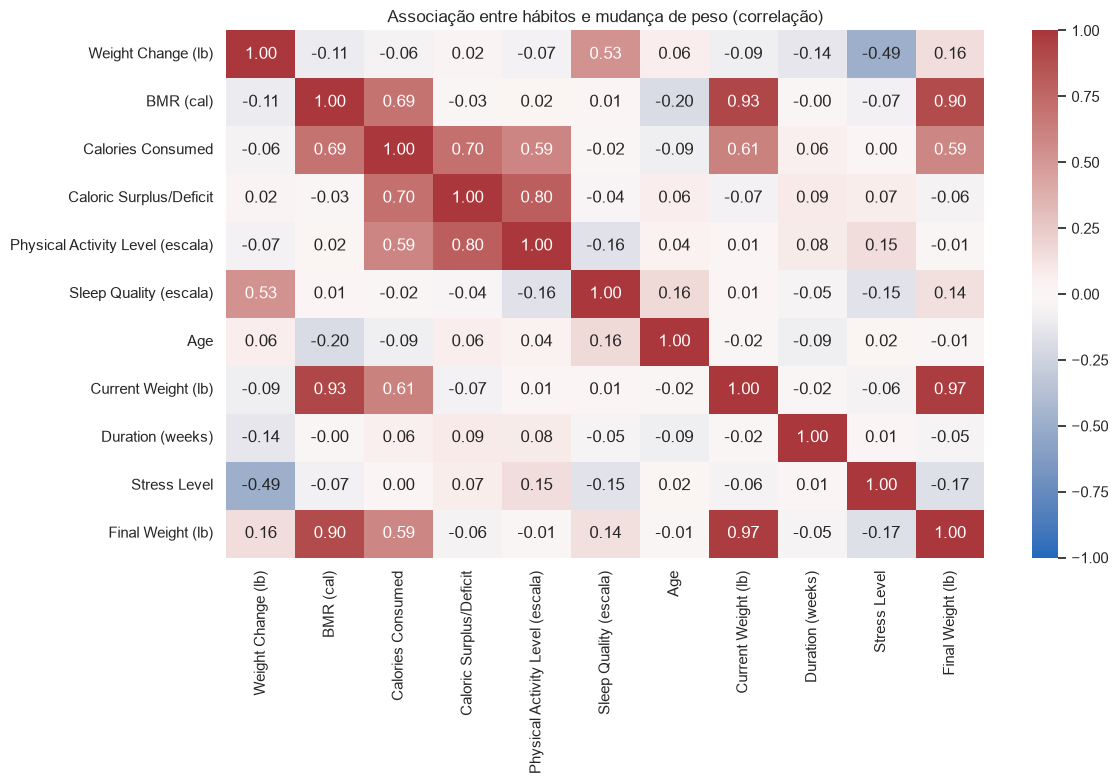

Pista descritiva: 'Sleep Quality (ordem aproximada)' e 'Weight Change (lbs)' sobem juntas nesta amostra (correlação 0.53). Isso não prova causa e efeito.
Associações mais fortes com hábitos registrados (não inclui o peso final):
 - Sleep Quality (ordem aproximada): correlação 0.53.
 - Stress Level: correlação -0.49.
 - Duration (weeks): correlação -0.14.
Uma mudança negativa quer dizer redução de peso registrada; positiva, aumento.
Qualidade do sono é uma escala em palavras convertida em ordem (ruim a excelente), não horas dormidas.
A cor representa associação, não importância de um modelo nem prova de causa.
O conjunto tem 100 pessoas; uma correlação pode mudar bastante se algumas respostas forem diferentes.


In [27]:
# O heatmap pinta números que mostram se duas medidas caminham juntas nesta amostra.
numericas_rafael = df_rafael_analise.select_dtypes(include="number").copy()
colunas_id = [
    coluna for coluna in numericas_rafael.columns
    if "id" in normalizar_texto(coluna) or "participant" in normalizar_texto(coluna)
]
# O ID só identifica pessoas; sua ordem não é um hábito e não deve entrar na correlação.
numericas_rafael = numericas_rafael.drop(columns=colunas_id, errors="ignore")

# Mostramos primeiro os campos ligados à pergunta e depois os outros campos numéricos.
colunas_prioritarias = list(dict.fromkeys(
    colunas_peso + colunas_calorias + colunas_atividade + colunas_sono_rafael
))
colunas_prioritarias = [coluna for coluna in colunas_prioritarias if coluna in numericas_rafael.columns]
colunas_heatmap = list(dict.fromkeys(colunas_prioritarias + list(numericas_rafael.columns)))[:12]
matriz_rafael = numericas_rafael[colunas_heatmap].corr(min_periods=3)

if matriz_rafael.shape[0] >= 2:
    nomes_curto_rafael = {
        coluna: str(coluna)
        .replace("Daily ", "")
        .replace(" (ordem aproximada)", " (escala)")
        .replace(" (lbs)", " (lb)")
        .replace(" (Calories)", " (cal)")
        for coluna in matriz_rafael.columns
    }
    matriz_visual = matriz_rafael.rename(index=nomes_curto_rafael, columns=nomes_curto_rafael)
    plt.figure(figsize=(12, 8))
    sns.heatmap(matriz_visual, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f")
    plt.title("Associação entre hábitos e mudança de peso (correlação)")
    plt.tight_layout()
    plt.show()
else:
    print("Não há pelo menos duas colunas numéricas para montar o heatmap.")

if colunas_peso:
    alvo_peso = colunas_peso[0]
    if alvo_peso in matriz_rafael.columns:
        insight_correlacao(matriz_rafael, alvo_peso)
        relacoes_peso = matriz_rafael[alvo_peso].drop(labels=[alvo_peso], errors="ignore").dropna()
        palavras_habito = (
            "caloriesconsumed", "surplusdeficit", "physicalactivity", "sleepquality",
            "stresslevel", "duration",
        )
        colunas_habitos = [
            coluna for coluna in relacoes_peso.index
            if any(palavra in normalizar_texto(coluna) for palavra in palavras_habito)
        ]
        relacoes_habitos = relacoes_peso[colunas_habitos]
        relacoes_habitos = relacoes_habitos.reindex(
            relacoes_habitos.abs().sort_values(ascending=False).index
        )
        print("Associações mais fortes com hábitos registrados (não inclui o peso final):")
        for coluna, valor in relacoes_habitos.head(3).items():
            print(f" - {coluna}: correlação {valor:.2f}.")
        print("Uma mudança negativa quer dizer redução de peso registrada; positiva, aumento.")
        print("Qualidade do sono é uma escala em palavras convertida em ordem (ruim a excelente), não horas dormidas.")
    else:
        print(f"A mudança de peso ({alvo_peso}) existe, mas não está como número utilizável para correlação.")
else:
    alvo_peso = None
    print("Sem uma coluna de mudança de peso, não podemos comparar hábitos com o resultado.")

if not colunas_atividade:
    print("O arquivo não trouxe uma medida clara de minutos ou nível de atividade física.")
if not colunas_sono_rafael:
    print("O arquivo não trouxe horas/qualidade do sono com um nome reconhecível.")
print("A cor representa associação, não importância de um modelo nem prova de causa.")
print("O conjunto tem 100 pessoas; uma correlação pode mudar bastante se algumas respostas forem diferentes.")

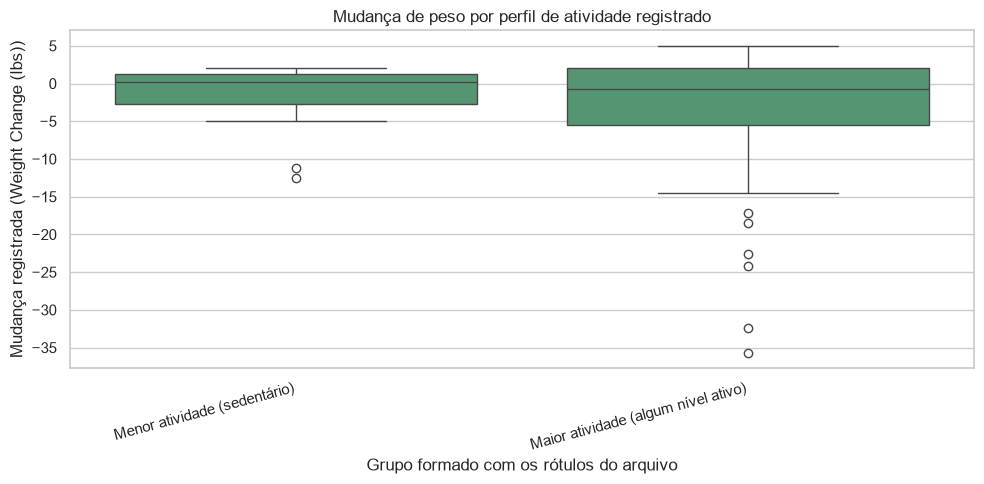

,count,median,mean,min,max
perfil_atividade,,,,,
Maior atividade (algum nível ativo),79,-0.736117,-3.132261,-35.678115,5.0
Menor atividade (sedentário),21,0.200000,-1.453954,-12.513498,2.0


Como ler: mediana negativa indica redução registrada; positiva indica aumento registrado.
Compare também quantas pessoas há em cada grupo; grupos pequenos deixam a comparação instável.
Nesta amostra, a mediana mais baixa foi em 'Maior atividade (algum nível ativo)' (-0.74 lb) e a mais alta em 'Menor atividade (sedentário)' (0.20 lb). Isso descreve o grupo, não prova causa.


In [28]:
if not colunas_peso or not colunas_atividade:
    print("Não dá para comparar atividade e mudança de peso: falta uma das duas medidas no arquivo.")
else:
    coluna_atividade = colunas_atividade[0]
    coluna_mudanca = colunas_peso[0]
    atividade_original = df_rafael_analise[coluna_atividade]
    mudanca = pd.to_numeric(df_rafael_analise[coluna_mudanca], errors="coerce")
    tabela_comparacao = pd.DataFrame({"atividade": atividade_original, "mudanca_peso": mudanca})

    atividade_num = pd.to_numeric(atividade_original, errors="coerce")
    if atividade_num.notna().sum() >= 3:
        # A mediana divide esta amostra em duas metades; não é uma recomendação de saúde.
        centro = atividade_num.median()
        tabela_comparacao["perfil_atividade"] = np.where(
            atividade_num <= centro, "Até a mediana da amostra", "Acima da mediana da amostra"
        )
        print(f"Atividade numérica: usamos {centro:.2f} como divisão entre as metades, não como corte clínico.")
    else:
        # Se o arquivo já nomeia os grupos, usamos esses nomes em vez de inventar minutos.
        resposta = atividade_original.astype("string").str.strip()
        normalizada = resposta.fillna("").map(normalizar_texto)
        tabela_comparacao["perfil_atividade"] = resposta
        tabela_comparacao.loc[
            normalizada.str.contains("sedent|inactive|low|baixo|pouco"), "perfil_atividade"
        ] = "Menor atividade (sedentário)"
        tabela_comparacao.loc[
            normalizada.str.contains("active|high|alto|moderate|moderado"), "perfil_atividade"
        ] = "Maior atividade (algum nível ativo)"

    tabela_comparacao = tabela_comparacao.dropna(subset=["perfil_atividade", "mudanca_peso"])
    if tabela_comparacao["perfil_atividade"].nunique() >= 2 and not tabela_comparacao.empty:
        sns.boxplot(data=tabela_comparacao, x="perfil_atividade", y="mudanca_peso", color="#4C9F70")
        plt.title("Mudança de peso por perfil de atividade registrado")
        plt.xlabel("Grupo formado com os rótulos do arquivo")
        plt.ylabel(f"Mudança registrada ({coluna_mudanca})")
        plt.xticks(rotation=15, ha="right")
        plt.tight_layout()
        plt.show()
        resumo_atividade = tabela_comparacao.groupby("perfil_atividade", observed=False)["mudanca_peso"].agg(
            ["count", "median", "mean", "min", "max"]
        )
        display(resumo_atividade)
        print("Como ler: mediana negativa indica redução registrada; positiva indica aumento registrado.")
        print("Compare também quantas pessoas há em cada grupo; grupos pequenos deixam a comparação instável.")
        if len(resumo_atividade) == 2:
            medianas = resumo_atividade["median"]
            grupo_menor = medianas.idxmin()
            grupo_maior = medianas.idxmax()
            print(
                f"Nesta amostra, a mediana mais baixa foi em '{grupo_menor}' "
                f"({medianas[grupo_menor]:.2f} lb) e a mais alta em '{grupo_maior}' "
                f"({medianas[grupo_maior]:.2f} lb). Isso descreve o grupo, não prova causa."
            )
    else:
        print("A coluna de atividade existe, mas só há um grupo utilizável para comparar.")

In [29]:
# “Consistência” significa repetir um hábito ao longo do tempo, então procuramos registros repetidos por pessoa.
colunas_id_rafael = [
    coluna for coluna in df_rafael_analise.columns
    if "participantid" in normalizar_texto(coluna) or normalizar_texto(coluna) == "id"
]
if colunas_id_rafael:
    coluna_id_rafael = colunas_id_rafael[0]
    pessoas_repetidas = df_rafael_analise[coluna_id_rafael].duplicated(keep=False).sum()
    print(f"Registros ligados a IDs repetidos: {pessoas_repetidas}.")
else:
    pessoas_repetidas = 0
    print("Não encontrei um identificador de pessoa para verificar medições repetidas.")

if pessoas_repetidas == 0:
    print("Sem medições repetidas ao longo do tempo, não dá para provar quais hábitos foram sustentáveis.")

# Um saldo positivo/negativo permite comparar apenas as categorias registradas, sem chamar isso de dieta.
colunas_saldo = [
    coluna for coluna in colunas_calorias
    if any(palavra in normalizar_texto(coluna) for palavra in ("surplus", "deficit", "balance"))
]
if alvo_peso and colunas_saldo:
    coluna_saldo = colunas_saldo[0]
    saldo = pd.to_numeric(df_rafael_analise[coluna_saldo], errors="coerce")
    comparacao_saldo = pd.DataFrame({"saldo": saldo, "mudanca_peso": pd.to_numeric(df_rafael_analise[alvo_peso], errors="coerce")})
    comparacao_saldo["faixa_saldo"] = np.select(
        [comparacao_saldo["saldo"] < 0, comparacao_saldo["saldo"] > 0],
        ["Déficit registrado", "Superávit registrado"],
        default="Saldo zero/indefinido",
    )
    comparacao_saldo = comparacao_saldo.dropna(subset=["saldo", "mudanca_peso"])
    if comparacao_saldo["faixa_saldo"].nunique() >= 2:
        sns.boxplot(data=comparacao_saldo, x="faixa_saldo", y="mudanca_peso", color="#6A8CAF")
        plt.title("Mudança de peso por faixa de saldo calórico registrada")
        plt.xlabel("Categoria descritiva do saldo")
        plt.ylabel(alvo_peso)
        plt.tight_layout()
        plt.show()
        display(comparacao_saldo.groupby("faixa_saldo", observed=False)["mudanca_peso"].agg(["count", "median", "mean"]))
        print("Se a mudança de peso foi calculada usando esse saldo, a semelhança pode vir da fórmula, não de uma descoberta nova.")
    else:
        print("Há uma coluna de saldo, mas não há categorias suficientes para comparar.")
else:
    print("Não encontrei saldo calórico e mudança de peso juntos; a comparação não será inventada.")

print("Conclusão desta seção: sem acompanhamento repetido e sem uma medida de adesão a dietas, estes dados não respondem se hábitos sustentáveis vencem dietas restritivas.")

Registros ligados a IDs repetidos: 0.
Sem medições repetidas ao longo do tempo, não dá para provar quais hábitos foram sustentáveis.
Há uma coluna de saldo, mas não há categorias suficientes para comparar.
Conclusão desta seção: sem acompanhamento repetido e sem uma medida de adesão a dietas, estes dados não respondem se hábitos sustentáveis vencem dietas restritivas.


## 9. Recomendações para gestão de tempo: Larissa e o Agente Sincronizador

A recomendação abaixo não vai fingir que o questionário mediu sono e produtividade. Ela separa o que este dataset mostra do que o CULTIVA poderia observar com consentimento no uso real: horários planejados, pausas, sono informado pela própria pessoa e tarefas concluídas. O agente deve sugerir ajustes pequenos, não dar bronca nem diagnóstico.

In [30]:
# O agente só comenta relações de sono e desempenho se os dois campos realmente existirem.
col_sono = colunas_por_pistas(df_larissa, pistas_sono)
col_desempenho = colunas_por_pistas(df_larissa, pistas_desempenho)
if col_sono and col_desempenho:
    par = df_larissa[[col_sono[0], col_desempenho[0]]].apply(pd.to_numeric, errors="coerce").dropna()
    if len(par) >= 3 and par.nunique().min() > 1:
        correlacao_sono_desempenho = par.iloc[:, 0].corr(par.iloc[:, 1])
        print(f"Na amostra, '{col_sono[0]}' e '{col_desempenho[0]}' têm correlação {correlacao_sono_desempenho:.2f}.")
    else:
        print("Sono e desempenho aparecem, mas não há valores variados suficientes para comparar.")
else:
    print("Este dataset não permite medir uma relação entre sono e produtividade: falta uma ou ambas as colunas.")

print(
    "\nAgente Sincronizador (simulação): ‘Larissa, vamos olhar sua semana com calma. "
    "Se você autorizar o CULTIVA a acompanhar seu próprio horário de descanso e suas tarefas, "
    "posso perceber quando o plano está cheio demais e sugerir uma pausa ou mover uma tarefa. "
    "Não vou concluir que dormir pouco causa uma nota menor usando este questionário, porque ele não mede essas horas. "
    "Você escolhe se aceita a sugestão.’"
)

Este dataset não permite medir uma relação entre sono e produtividade: falta uma ou ambas as colunas.

Agente Sincronizador (simulação): ‘Larissa, vamos olhar sua semana com calma. Se você autorizar o CULTIVA a acompanhar seu próprio horário de descanso e suas tarefas, posso perceber quando o plano está cheio demais e sugerir uma pausa ou mover uma tarefa. Não vou concluir que dormir pouco causa uma nota menor usando este questionário, porque ele não mede essas horas. Você escolhe se aceita a sugestão.’


## 10. Recomendações para mudança de peso: Rafael

O app pode transformar um objetivo grande em um passo que caiba no dia, como registrar uma caminhada curta ou planejar um horário de descanso. Os dados aqui não mostram sozinhos se uma dieta é sustentável nem dizem o que é seguro para cada pessoa; metas de saúde devem respeitar a pessoa e, quando necessário, orientação profissional. A contagem de calorias pode ser uma informação opcional, não a única medida de progresso.

In [31]:
# Este resumo usa valores reais calculados acima, mas continua sendo apenas descritivo.
if alvo_peso and alvo_peso in df_rafael_analise.columns:
    valores_peso = pd.to_numeric(df_rafael_analise[alvo_peso], errors="coerce").dropna()
    if not valores_peso.empty:
        print(
            f"A coluna '{alvo_peso}' tem {len(valores_peso)} valores utilizáveis; "
            f"a mediana observada é {valores_peso.median():.2f} e o intervalo interquartil vai de "
            f"{valores_peso.quantile(0.25):.2f} a {valores_peso.quantile(0.75):.2f}."
        )
else:
    print("Não há uma medida reconhecível de mudança de peso para resumir.")

if colunas_atividade:
    print(f"Campo de atividade disponível para orientar perguntas do app: {colunas_atividade[0]}.")
else:
    print("Sem uma coluna de atividade, este conjunto não orienta metas de exercício diretamente.")

print(
    "\nRecomendação para o CULTIVA: oferecer uma escolha pequena e negociável, "
    "acompanhar como a própria pessoa se sente ao longo de várias semanas e celebrar regularidade. "
    "Não prometer perda de peso, não chamar correlação de causa e não transformar um valor extremo em diagnóstico. "
    "Como a amostra é pequena e a mudança pode ter sido estimada a partir do saldo calórico, "
    "o app deve usar estes resultados para formular perguntas e hipóteses, não para impor uma regra a todos."
)

print("\nFontes: KaggleHub xiaowenlimarketing/international-student-time-management e abdullah0a/comprehensive-weight-change-prediction.")

A coluna 'Weight Change (lbs)' tem 100 valores utilizáveis; a mediana observada é 0.10 e o intervalo interquartil vai de -5.01 a 1.85.
Campo de atividade disponível para orientar perguntas do app: Physical Activity Level.

Recomendação para o CULTIVA: oferecer uma escolha pequena e negociável, acompanhar como a própria pessoa se sente ao longo de várias semanas e celebrar regularidade. Não prometer perda de peso, não chamar correlação de causa e não transformar um valor extremo em diagnóstico. Como a amostra é pequena e a mudança pode ter sido estimada a partir do saldo calórico, o app deve usar estes resultados para formular perguntas e hipóteses, não para impor uma regra a todos.

Fontes: KaggleHub xiaowenlimarketing/international-student-time-management e abdullah0a/comprehensive-weight-change-prediction.
